# Proyek Analisis Data: Bike-sharing-dataset
- **Nama:** I Made Dwira Dwijanata
- **Email:** ds014b6y0757@student.devacademy.id
- **ID Dicoding:** I Made Dwira Dwijanata DS014B6Y0757

**Latar belakang dataset:** Bike Sharing Dataset berisi data penyewaan sepeda dari sistem Capital Bikeshare di Washington D.C., Amerika Serikat, sepanjang 2011–2012. Pengguna mengambil sepeda di stasiun, mengayuh sendiri, lalu mengembalikannya di stasiun mana pun. Data tersedia dalam dua tingkat: per jam (hour.csv, 17.379 baris) dan per hari (day.csv, 731 baris), dilengkapi informasi cuaca dan kalender.

## Menentukan Pertanyaan Bisnis

**SMART Question** adalah sebuah framework untuk merumuskan pertanyaan secara terstruktur agar memeperoleh informasi yang mendalam.

* **Spesific (Spesifik)**
  * Pertanyaan harus jelas, fokus pada sebuah topik tertentu, dan tidak bermakna ganda. Hindari pertanyaan yang terlalu luas.
    * Salah: Bagaimana cara meningkatkan penjualan?
    * Benar: Faktor apa saja yang memengaruhi penurunan penjualan produk kategori elektronik di wilayah Jakarta selama kuartal terakhir?
* **Measurable (Terukur)**
  * Pertanyaan harus bisa dijawab dengan angka atau matrix yang konkret, harus tahu apa yang akan dihitung.
    * Salah: Apakah pelanggan senang dengan layanan kita?
    * Benar: Berapa skor rata-rata Customer Satisfaction untuk layanan purna jual bulan ini dibandingkan bulan lalu?
* **Action-Oriented (Berorientasi Aksi)**
  * Hasil dari pertanyaan harus bisa memberikan arahan untuk melakukan tindakan nyata. Jika pertanyaan terjawab, stakeholder harus tahu apa langkah selanjutnya.
    * Salah: Mengapa orang suka berbelanja?
    * Benar: Fitur apa pada aplikasi yang paling sering digunakan sebelum pengguna memutuskan untuk melakukan checkout?
* **Relevant (Relevan)**
  * Hasil dari pertanyaan harus sejalan dengan tujuan utama bisnis atau masalah yang sedang dihadapi.
    * Salah: Menanyakan tentang stok gudang saat masalah utamanya adalah efektivitas kampanye media sosial.
    * Benar: Apakah kampanye iklan di Instagram memberikan Return on Ad Spend (ROAS) yang lebih tinggi dibandingkan iklan di TikTok?
* **Time-bound (Terikat Waktu)**
  * Pertanyaan harus ada batasan waktu yang jelas agar analisis memiliki konteks yang tepat.
    * Salah: Berapa banyak pengguna baru kita?
    * Benar: Berapa tingkat pertumbuhan pengguna baru secara bulanan (Month-over-Month) sepanjang tahun 2025?

**Contoh pertanyaan bisnis yang memenuhi seluruh elemen SMART**

***"Faktor apa saja yang memengaruhi penurunan conversion rate pada pengguna aplikasi Android di wilayah Jabodetabek sebesar 5% selama periode Flash Sale Maret 2026?"***

Keterangan:

- **Specific**: Fokus pada "penurunan conversion rate" untuk "aplikasi Android" di "Jabodetabek". Bukan sekadar penjualan turun.
- **Measurable**: Ada angka konkret yang ingin dianalisis, yaitu penurunan sebesar "5%".
- **Action-Oriented**: Dengan mengetahui faktor penyebabnya misalnya bug pada versi Android tertentu atau kendala logistik di Jabodetabek, tim bisa langsung melakukan perbaikan teknis atau operasional.
- **Relevant**: Penurunan konversi saat Flash Sale adalah masalah kritis bagi bisnis retail/e-commerce.
- **Time-bound**: Dibatasi pada periode spesifik "Flash Sale Maret 2026".

- **Pertanyaan 1:** Pada jam berapa rata-rata penyewaan sepeda per jam (cnt) mencapai puncak pada hari kerja dibandingkan akhir pekan/hari libur sepanjang 2011–2012, dan berapa selisih rata-ratanya pada tiap segmen waktu (Dini Hari, Pagi Sibuk, Siang, Sore Sibuk, Malam), agar distribusi dan perawatan sepeda dapat dijadwalkan di luar jam puncak?

- **Pertanyaan 2:** Seberapa besar pengaruh kondisi cuaca (weathersit) dan kategori suhu (Dingin, Sejuk, Hangat, Panas) terhadap rata-rata penyewaan harian (cnt) sepanjang 2011–2012, dan kombinasi kondisi mana yang menghasilkan penyewaan terendah, agar operator dapat menyiapkan promo atau menyesuaikan stok sepeda pada kondisi tersebut?

- **Pertanyaan 3:** Berapa persen pertumbuhan total penyewaan per bulan pada 2012 dibandingkan bulan yang sama di 2011, dan bulan mana yang tumbuh paling lambat, agar target dan kampanye bulanan 2013 dapat disusun?

In [85]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Import Semua Packages/Library yang Digunakan

In [86]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

## Data Wrangling

### Gathering Data

#### Load day_df dan hour_d

In [87]:
day_df = pd.read_csv("/content/drive/MyDrive/submission/data/day.csv")
hour_df = pd.read_csv("/content/drive/MyDrive/submission/data/hour.csv")

print("Ukuran day_df  :", day_df.shape)
print("Ukuran hour_df :", hour_df.shape)
display(day_df.head())
display(hour_df.head())

Ukuran day_df  : (731, 16)
Ukuran hour_df : (17379, 17)


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


**Insight:** (Opsional)
- day_df berisi 731 baris dan 16 kolom (data harian 2011–2012), sedangkan hour_df berisi 17.379 baris dan 17 kolom (data per jam).
- hour_df memiliki satu kolom tambahan, yaitu hr (jam), yang dibutuhkan untuk menjawab pertanyaan 1.
- Kolom temp, atemp, hum, dan windspeed masih dalam skala ternormalisasi, sedangkan season, weathersit, dan yr masih berupa kode angka. Hal ini akan ditangani di tahap Cleaning.

### Assessing Data

#### Identifying data quality problems

In [88]:
# 1. Tipe data, missing value, dan duplikat
for name, df in [("day_df", day_df), ("hour_df", hour_df)]:
    print(f"=== {name} ===")
    df.info()
    print("Total missing value:", df.isna().sum().sum())
    print("Data duplikat      :", df.duplicated().sum(), "\n")

=== day_df ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null    float64
 13  casual      731 non-null    int64  
 14  registered  731 non-null    int64  
 15  cnt         731 non-null    int64  
dtypes: float64(4), int64(11), object(1)
memory usage: 91.5+ KB
Total missing value: 0
Data duplikat      : 0 

=== hour_df ===
<class 'pandas

In [89]:
# 2. Invalid value: kelembapan (hum) tidak mungkin 0
print(day_df[day_df["hum"] == 0][["dteday", "hum", "cnt"]])
print("Jumlah hum == 0 di hour_df:", (hour_df["hum"] == 0).sum())

        dteday  hum  cnt
68  2011-03-10  0.0  623
Jumlah hum == 0 di hour_df: 22


In [90]:
# 3. Kelengkapan data per jam
print("Baris hour_df :", len(hour_df))
print("Seharusnya    :", 731 * 24)
print("Selisih       :", 731 * 24 - len(hour_df))
print("cnt minimum di hour_df:", hour_df["cnt"].min())

Baris hour_df : 17379
Seharusnya    : 17544
Selisih       : 165
cnt minimum di hour_df: 1


In [91]:
# 4. Konsistensi kode kategori
print(pd.crosstab(day_df["mnth"], day_df["season"]))
print(day_df["weathersit"].value_counts())
print(hour_df["weathersit"].value_counts())

season   1   2   3   4
mnth                  
1       62   0   0   0
2       57   0   0   0
3       40  22   0   0
4        0  60   0   0
5        0  62   0   0
6        0  40  20   0
7        0   0  62   0
8        0   0  62   0
9        0   0  44  16
10       0   0   0  62
11       0   0   0  60
12      22   0   0  40
weathersit
1    463
2    247
3     21
Name: count, dtype: int64
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


In [92]:
# 5. Outlier (metode IQR)
for col in ["cnt", "casual", "windspeed"]:
    q1, q3 = day_df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((day_df[col] < q1 - 1.5 * iqr) | (day_df[col] > q3 + 1.5 * iqr)).sum()
    print(f"Outlier {col}: {n}")
print(day_df.nsmallest(3, "cnt")[["dteday", "weathersit", "cnt"]])

Outlier cnt: 0
Outlier casual: 44
Outlier windspeed: 13
         dteday  weathersit  cnt
667  2012-10-29           3   22
26   2011-01-27           1  431
725  2012-12-26           3  441


**Steps to Take:**
- Mengubah tipe data dteday dari string menjadi datetime.

- Mengganti nilai hum = 0 (invalid) dengan median hum pada bulan yang sama.

- Melabeli ulang season berdasarkan pola data (1 = Dingin, 2 = Semi, 3 = Panas, 4 = Gugur) karena label di Readme tidak sesuai.

- Mengonversi temp, atemp, hum, dan windspeed ke skala aslinya dan memberi label pada kode weathersit.

- Mempertahankan outlier karena mencerminkan kejadian nyata (misalnya Badai Sandy pada 2012-10-29), bukan kesalahan input.

- Jam tanpa penyewaan tidak tercatat di hour_df, sehingga rata-rata per jam dihitung dari jam yang tercatat dan dicatat sebagai keterbatasan.

**Insight:** (Opsional)
- Tidak ditemukan missing value maupun data duplikat pada kedua dataset.
- Ditemukan invalid value pada hum (bernilai 0): 1 baris di day_df dan 22 baris di hour_df.
- hour_df hanya memuat 17.379 dari 17.544 jam yang mungkin, kemungkinan karena jam tanpa penyewaan tidak dicatat.
- Label season pada Readme tidak sesuai isi data (season 1 jatuh pada Januari–Maret).
- Outlier pada casual dan windspeed mencerminkan kondisi nyata, bukan error, sehingga tidak dihapus.

### Cleaning Data

#### Fixing data type problem (dteday)

In [93]:
for df in (day_df, hour_df):
    df["dteday"] = pd.to_datetime(df["dteday"])

print(day_df["dteday"].dtype, hour_df["dteday"].dtype)

datetime64[ns] datetime64[ns]


#### Fixing invalid value problem (hum = 0)

In [94]:
for df in (day_df, hour_df):
    df["hum"] = df["hum"].replace(0, np.nan)
    df["hum"] = df["hum"].fillna(df.groupby("mnth")["hum"].transform("median"))

print("hum == 0 tersisa:", (day_df["hum"] == 0).sum(), (hour_df["hum"] == 0).sum())
print("hum kosong      :", day_df["hum"].isna().sum(), hour_df["hum"].isna().sum())

hum == 0 tersisa: 0 0
hum kosong      : 0 0


#### Fixing scale and label problem

In [95]:
for df in (day_df, hour_df):
    # skala asli (nilai ternormalisasi x pembagi dari Readme)
    df["temp_c"] = df["temp"] * 41
    df["atemp_c"] = df["atemp"] * 50
    df["hum_pct"] = df["hum"] * 100
    df["windspeed_kmh"] = df["windspeed"] * 67

    # label kategori
    df["year"] = df["yr"].map({0: 2011, 1: 2012})
    df["season_label"] = df["season"].map({1: "Dingin", 2: "Semi", 3: "Panas", 4: "Gugur"})
    df["weather_label"] = df["weathersit"].map({
        1: "Cerah", 2: "Berkabut/Berawan",
        3: "Hujan/Salju Ringan", 4: "Hujan/Salju Lebat"})
    df["day_type"] = np.where(df["workingday"] == 1, "Hari Kerja", "Akhir Pekan/Libur")

day_df[["dteday", "temp_c", "hum_pct", "windspeed_kmh", "year",
        "season_label", "weather_label", "day_type"]].head()

,dteday,temp_c,hum_pct,windspeed_kmh,year,season_label,weather_label,day_type
0,2011-01-01,14.110847,80.5833,10.749882,2011,Dingin,Berkabut/Berawan,Akhir Pekan/Libur
1,2011-01-02,14.902598,69.6087,16.652113,2011,Dingin,Berkabut/Berawan,Akhir Pekan/Libur
2,2011-01-03,8.050924,43.7273,16.636703,2011,Dingin,Cerah,Hari Kerja
3,2011-01-04,8.200000,59.0435,10.739832,2011,Dingin,Cerah,Hari Kerja
4,2011-01-05,9.305237,43.6957,12.522300,2011,Dingin,Cerah,Hari Kerja


**Insight:** (Opsional)
- Kolom dteday berhasil diubah menjadi datetime sehingga siap untuk analisis berbasis waktu.

- Seluruh nilai hum = 0 diganti dengan median hum pada bulan yang sama, sehingga tidak ada lagi nilai invalid.

- Kolom temp, atemp, hum, dan windspeed dikonversi ke skala asli, dan kode season, weathersit, serta yr diberi label agar mudah dibaca.

- Kolom day_type (Hari Kerja vs Akhir Pekan/Libur) ditambahkan untuk mendukung analisis pertanyaan 1.

- Outlier tidak dihapus karena mencerminkan kejadian nyata, dan data siap dipakai untuk EDA.

## Exploratory Data Analysis (EDA)

### Explore Pertanyaan 1: Pola Penyewaan per Jam (Hari Kerja vs Akhir Pekan/Libur)

In [96]:
# Rata-rata penyewaan per jam, per kategori hari
avg_hour = hour_df.groupby(["day_type", "hr"])["cnt"].mean().unstack(0).round(1)

# Jam puncak tiap jenis hari
for tipe in avg_hour.columns:
    jam = avg_hour[tipe].idxmax()
    print(f"{tipe}: puncak pada pukul {jam:02d}:00 "
          f"dengan rata-rata {avg_hour[tipe].max():.1f} sewa per jam")

Akhir Pekan/Libur: puncak pada pukul 13:00 dengan rata-rata 372.7 sewa per jam
Hari Kerja: puncak pada pukul 17:00 dengan rata-rata 525.3 sewa per jam


In [97]:
# Pengelompokan jam menjadi segmen waktu (binning)
hour_df["segmen"] = pd.cut(
    hour_df["hr"], bins=[-1, 5, 9, 15, 19, 23],
    labels=["Dini Hari (0-5)", "Pagi Sibuk (6-9)", "Siang (10-15)",
            "Sore Sibuk (16-19)", "Malam (20-23)"])

# Rata-rata sewa per jam untuk tiap segmen dan jenis hari
segmen_df = hour_df.groupby(["segmen", "day_type"], observed=True)["cnt"].mean().unstack()
segmen_df = segmen_df[["Hari Kerja", "Akhir Pekan/Libur"]]
segmen_df["Selisih"] = segmen_df["Hari Kerja"] - segmen_df["Akhir Pekan/Libur"]

# Rapikan header: hapus nama sumbu ganda
segmen_df.columns.name = None
segmen_df.index.name = "Segmen Waktu"

# Menampilkan table
(segmen_df.style
    .format("{:.1f}")
    .format("{:+.1f}", subset=["Selisih"])
    .set_caption("Rata-rata penyewaan sepeda per jam (sewa/jam) menurut segmen waktu dan jenis hari, 2011-2012")
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "14px"), ("font-weight", "bold"),
                                          ("text-align", "left"), ("padding-bottom", "8px")]},
        {"selector": "th", "props": [("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]},
    ]))

,Hari Kerja,Akhir Pekan/Libur,Selisih
Segmen Waktu,,,
Dini Hari (0-5),16.4,43.0,-26.6
Pagi Sibuk (6-9),277.9,85.0,+192.9
Siang (10-15),179.7,338.9,-159.3
Sore Sibuk (16-19),414.8,297.3,+117.4
Malam (20-23),165.8,129.7,+36.1


**Cara membaca tabel:** setiap angka adalah rata-rata jumlah sepeda yang disewa **per jam** pada segmen waktu dan jenis hari tersebut. Selisih = Hari Kerja dikurangi Akhir Pekan/Libur; tanda **+** berarti hari kerja lebih ramai, tanda **−** berarti akhir pekan/libur lebih ramai. Rata-rata dihitung dari jam yang tercatat di dataset.

**Insight:**
- Hari kerja memiliki dua puncak: sore pukul 17:00 (525,3 sewa/jam) dan pagi pukul 08:00 (477,0), mengikuti jam komuter.
- Akhir pekan/libur memiliki satu puncak yang landai pada siang hari, tertinggi pukul 13:00 (372,7 sewa/jam).
- Selisih rata-rata hari kerja dikurangi akhir pekan: Pagi Sibuk +192,9; Sore Sibuk +117,4; Malam +36,1. Sebaliknya Siang −159,3 dan Dini Hari −26,6, artinya siang hari lebih ramai pada akhir pekan/libur.
- Rata-rata segmen Dini Hari dihitung dari jam yang tercatat saja (110 dari 165 jam yang tidak tercatat berada pada pukul 0–5), sehingga nilainya cenderung sedikit lebih tinggi dari kondisi sebenarnya.

### Explore Pertanyaan 2: Pengaruh Cuaca dan Suhu terhadap Penyewaan Harian

####Pengaruh Cuaca

In [98]:
cuaca_df = day_df.groupby("weather_label")["cnt"].agg(["count", "mean"]).round(1)
cuaca_df["selisih_vs_cerah_%"] = ((cuaca_df["mean"] / cuaca_df.loc["Cerah", "mean"] - 1) * 100).round(1)
cuaca_df

,count,mean,selisih_vs_cerah_%
weather_label,,,
Berkabut/Berawan,247,4035.9,-17.2
Cerah,463,4876.8,0.0
Hujan/Salju Ringan,21,1803.3,-63.0


**insight pengaruh cuaca :** tabel ini membandingkan rata-rata penyewaan sepeda harian pada tiga kondisi cuaca.
- **Jumlah Hari (count):** banyaknya hari dalam data dengan kondisi cuaca tersebut. Contoh: 463 hari cerah dari total 731 hari.
- **Rata-rata Sewa/Hari (mean):** rata-rata jumlah sepeda yang disewa dalam satu hari (cnt, gabungan pengguna casual dan registered). Contoh: pada hari cerah, rata-rata 4.876,8 sepeda disewa per hari.
- **Selisih vs Cerah (%):** seberapa jauh rata-rata cuaca tersebut dari hari Cerah (rata-rata tertinggi), dihitung dengan rumus:

$$\text{Selisih}_k = \left(\frac{\bar{C}_k}{\bar{C}_{Cerah}} - 1\right) \times 100\%$$

dengan $\bar{C}_k$ adalah rata-rata sewa per hari pada cuaca $k$ dan $\bar{C}_{Cerah}$ adalah rata-rata pada hari Cerah.

Contoh: Hujan/Salju Ringan −63,0% berarti penyewaannya 63,0% lebih rendah daripada hari Cerah.

#### Pengaruh suhu

In [99]:
day_df["kat_suhu"] = pd.cut(
    day_df["temp_c"], bins=[0, 10, 20, 30, 50],
    labels=["Dingin (<10°C)", "Sejuk (10-20°C)", "Hangat (20-30°C)", "Panas (>30°C)"])

suhu_df = day_df.groupby("kat_suhu", observed=True)["cnt"].agg(["count", "mean"]).round(1)
suhu_df["selisih_vs_hangat_%"] = ((suhu_df["mean"] / suhu_df.loc["Hangat (20-30°C)", "mean"] - 1) * 100).round(1)
suhu_df

,count,mean,selisih_vs_hangat_%
kat_suhu,,,
Dingin (<10°C),60,1677.8,-70.4
Sejuk (10-20°C),299,3692.3,-34.8
Hangat (20-30°C),300,5661.7,0.0
Panas (>30°C),72,5410.0,-4.4


**insight pengaruh suhu:**

 suhu udara rata-rata harian dikelompokkan (binning) menjadi empat kategori: Dingin (< 10°C), Sejuk (10–20°C), Hangat (20–30°C), dan Panas (> 30°C).
- **Jumlah Hari (count):** banyaknya hari pada kategori suhu tersebut. Contoh: 60 hari tergolong Dingin.
- **Rata-rata Sewa/Hari (mean):** rata-rata sepeda yang disewa dalam satu hari pada kategori itu. Contoh: pada hari Dingin, rata-rata 1.677,8 sepeda disewa per hari.
- **Selisih vs Hangat (%):** perbandingan dengan kategori Hangat (rata-rata tertinggi) memakai rumus yang sama seperti tabel cuaca, dengan $\bar{C}_{ref}$ = rata-rata kategori Hangat. Contoh: Dingin −70,4% berarti penyewaannya 70,4% lebih rendah daripada hari Hangat.

#### Kombinasi suhu dan cuaca

In [100]:
urutan_cuaca = ["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]

pivot_mean = day_df.pivot_table(index="kat_suhu", columns="weather_label",
                                values="cnt", aggfunc="mean", observed=True)[urutan_cuaca]
pivot_n = day_df.pivot_table(index="kat_suhu", columns="weather_label",
                             values="cnt", aggfunc="count", observed=True)[urutan_cuaca]

# Gabungkan jadi satu tabel dengan format "rata-rata (jumlah hari)"
def gabung(rata, n):
    if pd.isna(rata):
        return "-"
    return f"{rata:,.0f}".replace(",", ".") + f" ({int(n)} hari)"

kombinasi = pivot_mean.copy().astype(object)
for suhu in pivot_mean.index:
    for cuaca in pivot_mean.columns:
        kombinasi.loc[suhu, cuaca] = gabung(pivot_mean.loc[suhu, cuaca], pivot_n.loc[suhu, cuaca])

kombinasi.index.name = "Kategori Suhu"
kombinasi.columns.name = None

display(kombinasi.style
    .set_caption("Rata-rata sewa per hari (jumlah hari) menurut kategori suhu dan kondisi cuaca, 2011-2012")
    .set_table_styles([
        {"selector": "caption", "props": [("font-size", "14px"), ("font-weight", "bold"),
                                          ("text-align", "left"), ("padding-bottom", "8px")]},
        {"selector": "th", "props": [("text-align", "center")]},
        {"selector": "td", "props": [("text-align", "center")]},
    ]))

terendah = pivot_mean.stack().idxmin()
rata_terendah = f"{pivot_mean.stack().min():,.0f}".replace(",", ".")
print(f"Kombinasi terendah: {terendah[0]} + {terendah[1]} "
      f"({rata_terendah} sewa/hari, dari {int(pivot_n.loc[terendah[0], terendah[1]])} hari)")

,Cerah,Berkabut/Berawan,Hujan/Salju Ringan
Kategori Suhu,,,
Dingin (<10°C),1.758 (36 hari),1.631 (21 hari),1.039 (3 hari)
Sejuk (10-20°C),4.069 (176 hari),3.336 (112 hari),1.297 (11 hari)
Hangat (20-30°C),6.074 (187 hari),5.115 (106 hari),2.927 (7 hari)
Panas (>30°C),5.355 (64 hari),5.851 (8 hari),-


Kombinasi terendah: Dingin (<10°C) + Hujan/Salju Ringan (1.039 sewa/hari, dari 3 hari)


**Penjelasan tabel kombinasi:**

 tabel ini menggabungkan kategori suhu (baris) dengan kondisi cuaca (kolom). Setiap sel berisi *rata-rata jumlah sepeda yang disewa per hari*, diikuti *jumlah hari* yang mendasarinya dalam tanda kurung. Contoh: **6.074 (187 hari)** berarti pada 187 hari yang hangat dan cerah, rata-rata 6.074 sepeda disewa per hari. Tanda **-** berarti kombinasi tersebut tidak ada dalam data.

Rata-rata yang berasal dari hanya beberapa hari (misalnya 3 hari) kurang kuat untuk digeneralisasi, sehingga perlu ditafsirkan dengan hati-hati.

### Explore Pertanyaan 3: Pertumbuhan Penyewaan Bulanan 2012 terhadap 2011

Pertumbuhan dihitung dengan rumus:

$$\text{Growth}_m = \frac{C_{m,2012} - C_{m,2011}}{C_{m,2011}} \times 100\%$$

dengan $C_{m,y}$ adalah total penyewaan (cnt) pada bulan $m$ di tahun $y$.

In [101]:
monthly = day_df.pivot_table(index="mnth", columns="year", values="cnt", aggfunc="sum")
monthly["pertambahan"] = monthly[2012] - monthly[2011]
monthly["growth_pct"] = (monthly["pertambahan"] / monthly[2011] * 100).round(1)
monthly["kelipatan_x"] = (monthly[2012] / monthly[2011]).round(2)

# Bulan paling lambat dan paling tinggi (dihitung sebelum baris Total ditambahkan)
lambat = monthly["growth_pct"].idxmin()
tinggi = monthly["growth_pct"].idxmax()

# Baris Total seluruh bulan
total_2011 = monthly[2011].sum()
total_2012 = monthly[2012].sum()
monthly.loc["Total"] = [total_2011, total_2012, total_2012 - total_2011,
                        round((total_2012 - total_2011) / total_2011 * 100, 1),
                        round(total_2012 / total_2011, 2)]


tabel = monthly.copy()
tabel["pertambahan"] = "+" + tabel["pertambahan"].astype(int).astype(str)
tabel["growth_pct"] = "+" + tabel["growth_pct"].astype(str) + "%"
tabel["kelipatan_x"] = tabel["kelipatan_x"].astype(str) + "x"
tabel[2011] = tabel[2011].astype(int)
tabel[2012] = tabel[2012].astype(int)
display(tabel)

print("Bulan (angka) dengan pertumbuhan paling lambat:", lambat)
print("Bulan (angka) dengan pertumbuhan paling tinggi:", tinggi)

year,2011,2012,pertambahan,growth_pct,kelipatan_x
mnth,,,,,
1,38189,96744,+58555,+153.3%,2.53x
2,48215,103137,+54922,+113.9%,2.14x
3,64045,164875,+100830,+157.4%,2.57x
4,94870,174224,+79354,+83.6%,1.84x
5,135821,195865,+60044,+44.2%,1.44x
6,143512,202830,+59318,+41.3%,1.41x
7,141341,203607,+62266,+44.1%,1.44x
8,136691,214503,+77812,+56.9%,1.57x
9,127418,218573,+91155,+71.5%,1.72x


Bulan (angka) dengan pertumbuhan paling lambat: 6
Bulan (angka) dengan pertumbuhan paling tinggi: 3


**Insight Explore untuk Pertanyaan 3:**
- Total penyewaan naik dari 1.243.103 (2011) menjadi 2.049.576 (2012), bertambah 806.473 sepeda atau tumbuh +64,9% (sekitar 1,65 kali lipat).
- Seluruh bulan mengalami pertumbuhan positif, dengan pertumbuhan terendah masih di atas 40%.
- Pertumbuhan tertinggi terjadi pada Maret (+157,4%; 2,57x) dan Januari (+153,3%; 2,53x). Persentasenya besar karena basis penyewaan 2011 pada bulan-bulan tersebut masih kecil (64.045 dan 38.189).
- Pertumbuhan paling lambat terjadi pada Juni (+41,3%; 1,41x), diikuti Desember (+41,7%; 1,42x), Juli (+44,1%; 1,44x), dan Mei (+44,2%; 1,44x).
- Dari sisi jumlah sepeda, pertambahan terbesar terjadi pada Maret (+100.830) dan terkecil pada Desember (+36.390).

## Visualization & Explanatory Analysis

### Pertanyaan 1: Pola Penyewaan per Jam (Hari Kerja vs Akhir Pekan/Libur)

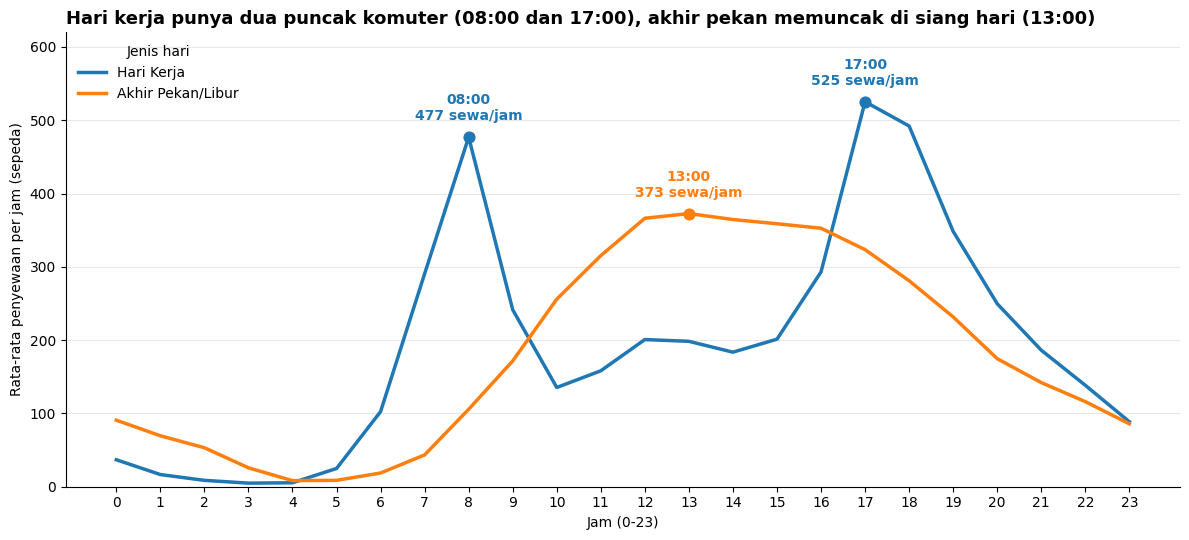

In [102]:
avg_hour = hour_df.groupby(["day_type", "hr"])["cnt"].mean().unstack(0).round(1)

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(avg_hour.index, avg_hour["Hari Kerja"], color="#1f77b4", linewidth=2.5, label="Hari Kerja")
ax.plot(avg_hour.index, avg_hour["Akhir Pekan/Libur"], color="#ff7f0e", linewidth=2.5, label="Akhir Pekan/Libur")

# Tandai jam puncak
puncak = [("Hari Kerja", 8, "#1f77b4"), ("Hari Kerja", 17, "#1f77b4"), ("Akhir Pekan/Libur", 13, "#ff7f0e")]
for tipe, jam, warna in puncak:
    nilai = avg_hour.loc[jam, tipe]
    ax.scatter(jam, nilai, color=warna, s=60, zorder=3)
    ax.annotate(f"{jam:02d}:00\n{nilai:.0f} sewa/jam", xy=(jam, nilai), xytext=(0, 12),
                textcoords="offset points", ha="center", color=warna, fontsize=10, fontweight="bold")

ax.set_title("Hari kerja punya dua puncak komuter (08:00 dan 17:00), akhir pekan memuncak di siang hari (13:00)",
             fontsize=13, fontweight="bold", loc="left")
ax.set_xlabel("Jam (0-23)")
ax.set_ylabel("Rata-rata penyewaan per jam (sepeda)")
ax.set_xticks(range(0, 24))
ax.set_ylim(0, 620)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Jenis hari", frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Penjelasan grafik:** sumbu horizontal adalah jam dalam sehari (0 = tengah malam, 23 = pukul 23:00) dan sumbu vertikal adalah rata-rata jumlah sepeda yang disewa pada jam itu. Garis biru adalah hari kerja dan garis oranye adalah akhir pekan/libur. Titik bertanda angka menunjukkan jam puncak.

**Jawaban Pertanyaan 1:** pada hari kerja penyewaan memuncak dua kali, pukul 08:00 (477 sewa/jam) dan pukul 17:00 (525 sewa/jam, tertinggi), sesuai jam berangkat dan pulang kerja.

Pada akhir pekan/libur penyewaan naik perlahan dan memuncak pukul 13:00 (373 sewa/jam), lalu turun menjelang malam. Pada pukul 10:00–15:00 akhir pekan lebih ramai daripada hari kerja, sedangkan pada pagi (06:00–09:00) dan sore (16:00–19:00) hari kerja jauh lebih ramai.

### Pertanyaan 2: Pengaruh Cuaca dan Suhu terhadap Penyewaan Harian

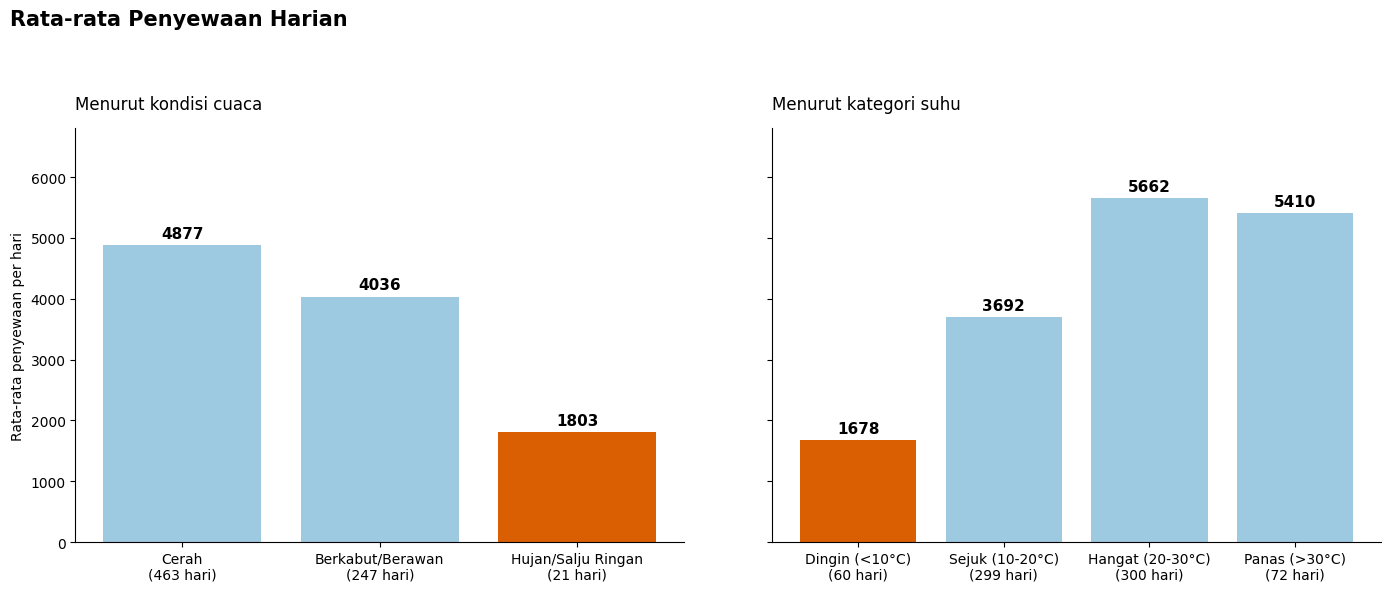

In [103]:
cuaca = day_df.groupby("weather_label")["cnt"].agg(["mean", "count"]).loc[["Cerah", "Berkabut/Berawan", "Hujan/Salju Ringan"]]
suhu = day_df.groupby("kat_suhu", observed=True)["cnt"].agg(["mean", "count"])

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)
panel = [(axes[0], cuaca, "Menurut kondisi cuaca"), (axes[1], suhu, "Menurut kategori suhu")]

for ax, data, judul in panel:
    warna = ["#9ecae1"] * len(data)
    warna[int(np.argmin(data["mean"].values))] = "#d95f02"   # sorot batang terendah
    label = [f"{nama}\n({int(n)} hari)" for nama, n in zip(data.index, data["count"])]
    batang = ax.bar(label, data["mean"], color=warna)
    ax.bar_label(batang, labels=[f"{v:.0f}" for v in data["mean"]],
                 padding=3, fontsize=11, fontweight="bold")
    ax.set_title(judul, fontsize=12, loc="left", pad=14)
    ax.set_ylim(0, 6800)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="x", labelsize=10)

axes[0].set_ylabel("Rata-rata penyewaan per hari")
fig.suptitle("Rata-rata Penyewaan Harian", fontsize=15, fontweight="bold", x=0.01, y=0.98, ha="left")
fig.tight_layout(rect=[0, 0, 1, 0.92], w_pad=6)
plt.show()

**Penjelasan grafik:** panel kiri membandingkan rata-rata penyewaan per hari menurut kondisi cuaca, panel kanan menurut kategori suhu. Angka di atas batang adalah rata-rata penyewaan per hari, dan angka dalam tanda kurung di bawah batang adalah jumlah hari yang mendasarinya. Batang oranye menandai kondisi dengan penyewaan terendah di tiap panel. Persentase pada judul dibandingkan dengan kondisi terbaik: Hujan/Salju Ringan terhadap Cerah (−63,0%) dan Dingin terhadap Hangat (−70,4%).

**Jawaban Pertanyaan 2:** cuaca dan suhu sama-sama berpengaruh kuat terhadap penyewaan. Cuaca Cerah rata-rata 4.877 penyewaan per hari, Berkabut/Berawan 4.036, dan Hujan/Salju Ringan hanya 1.803.

Menurut suhu, penyewaan naik dari Dingin (1.678) ke Sejuk (3.692), mencapai puncak pada Hangat (5.662), dan sedikit turun pada Panas (5.410).

Kombinasi terendah adalah Dingin + Hujan/Salju Ringan dengan rata-rata 1.039 penyewaan per hari, tetapi kombinasi itu hanya berasal dari 3 hari sehingga perlu ditafsirkan hati-hati.

### Pertanyaan 3: Pertumbuhan Penyewaan Bulanan 2012 terhadap 2011

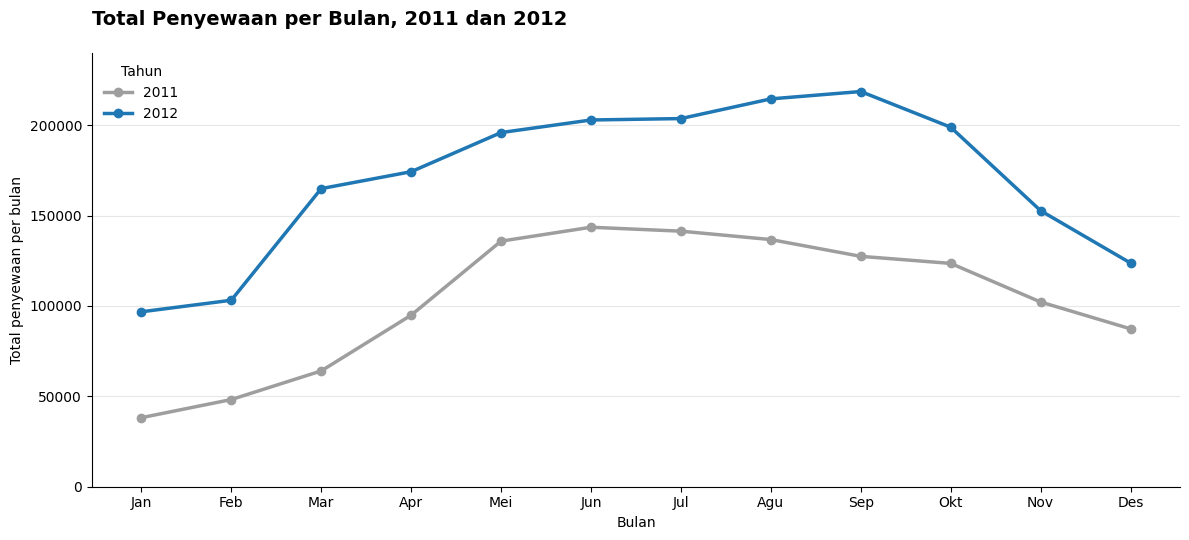

In [104]:
m = day_df.pivot_table(index="mnth", columns="year", values="cnt", aggfunc="sum")
m["growth_pct"] = (m[2012] - m[2011]) / m[2011] * 100
bulan = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(bulan, m[2011], color="#9e9e9e", linewidth=2.5, marker="o", label="2011")
ax.plot(bulan, m[2012], color="#1f77b4", linewidth=2.5, marker="o", label="2012")
ax.set_title("Total Penyewaan per Bulan, 2011 dan 2012", fontsize=14, fontweight="bold", loc="left", pad=20)
ax.set_xlabel("Bulan")
ax.set_ylabel("Total penyewaan per bulan")
ax.set_ylim(0, 240000)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(title="Tahun", frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

**Penjelasan grafik:**

Garis abu-abu adalah total penyewaan tiap bulan pada 2011 dan garis biru adalah total penyewaan tiap bulan pada 2012.

Garis 2012 berada di atas garis 2011 pada seluruh bulan.

**Jawaban Pertanyaan 3 (berdasarkan grafik 1):**

Total penyewaan naik dari 1.243.103 pada 2011 menjadi 2.049.576 pada 2012, bertambah 806.473 penyewaan atau tumbuh +64,9% (sekitar 1,6 kali lipat).

Penyewaan 2012 lebih tinggi daripada bulan yang sama di 2011 pada seluruh bulan.

Pada 2011 penyewaan bulanan tertinggi terjadi pada Juni (143.512), sedangkan pada 2012 tertinggi terjadi pada September (218.573).

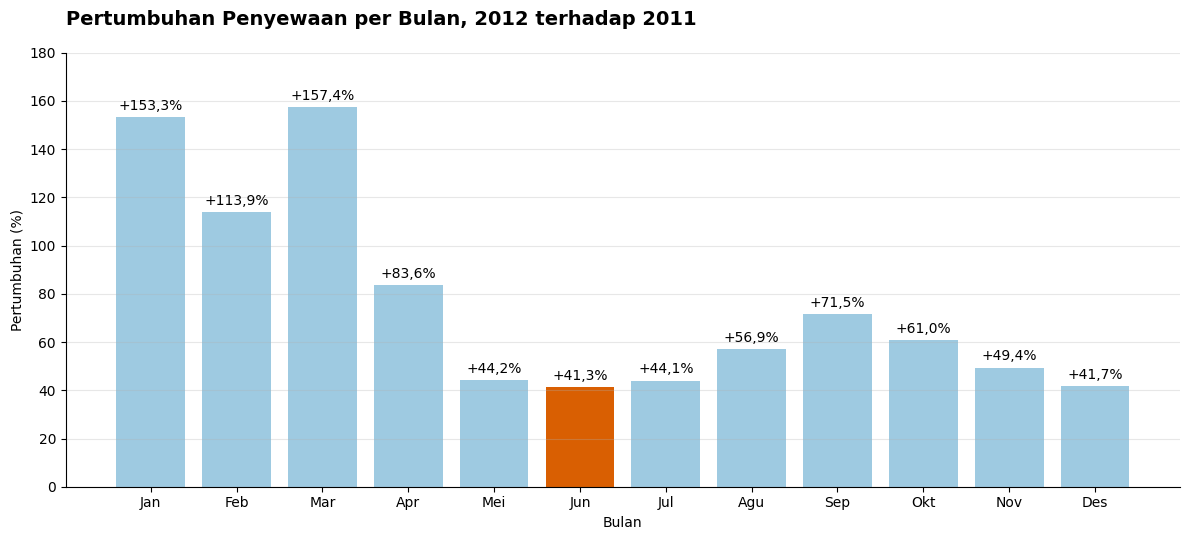

In [105]:
fig, ax = plt.subplots(figsize=(12, 5.5))
warna = ["#9ecae1"] * 12
warna[int(np.argmin(m["growth_pct"].values))] = "#d95f02"   # sorot bulan paling lambat
batang = ax.bar(bulan, m["growth_pct"], color=warna)
ax.bar_label(batang, labels=[f"+{v:.1f}%".replace(".", ",") for v in m["growth_pct"]], padding=3, fontsize=10)
ax.set_title("Pertumbuhan Penyewaan per Bulan, 2012 terhadap 2011", fontsize=14, fontweight="bold", loc="left", pad=20)
ax.set_xlabel("Bulan")
ax.set_ylabel("Pertumbuhan (%)")
ax.set_ylim(0, 180)
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Penjelasan grafik:**

Setiap batang adalah pertumbuhan penyewaan bulan tersebut di 2012 dibandingkan bulan yang sama di 2011, dalam persen.

Pertumbuhan 100% berarti penyewaan menjadi dua kali lipat.

Batang oranye menandai bulan dengan pertumbuhan paling lambat.

**Jawaban Pertanyaan 3 (berdasarkan grafik 2):**

Seluruh bulan tumbuh positif, dengan pertumbuhan terendah masih di atas 40%.

Pertumbuhan tertinggi terjadi pada Maret (+157,4%) dan Januari (+153,3%), tetapi penyewaan pada bulan itu di 2011 masih kecil (64.045 dan 38.189).

Pertumbuhan paling lambat terjadi pada Juni (+41,3%), diikuti Desember (+41,7%), Juli (+44,1%), dan Mei (+44,2%).

**Insight:**

- Permintaan punya dua pola yang berbeda menurut jenis hari. Hari kerja didorong kebutuhan berangkat dan pulang kerja (puncak pukul 08:00 sebesar 477,0 dan pukul 17:00 sebesar 525,3 penyewaan per jam), sedangkan akhir pekan/libur didorong aktivitas santai di siang hari (puncak pukul 13:00 sebesar 372,7).

- Penyewaan sangat sensitif terhadap kondisi lingkungan. Rata-rata harian turun dari 4877 pada cuaca Cerah menjadi 1803 saat Hujan/Salju Ringan, dan dari 5662 pada suhu Hangat menjadi 1678 saat Dingin.

- Penyewaan tertinggi muncul saat suhu Hangat (20–30°C) dan sedikit menurun saat Panas (>30°C), sehingga suhu paling nyaman bukan yang paling tinggi.

- Pada dua tahun data, penyewaan bulanan mengikuti pola musiman: naik dari awal tahun, tinggi pada pertengahan hingga akhir musim panas, lalu turun pada November–Desember. Pola ini sejalan dengan pengaruh suhu pada Pertanyaan 2, tetapi data ini belum membuktikan hubungan sebab-akibat.

- Sistem tumbuh pesat: total penyewaan naik dari 1.243.103 (2011) menjadi 2.049.576 (2012), atau +64,9% (sekitar 1,6 kali lipat), dan seluruh bulan tumbuh positif. Pertumbuhan paling lambat terjadi pada Juni (+41,3%).

- Keterbatasan: kondisi Hujan/Salju Ringan hanya terjadi pada 21 hari, rata-rata segmen Dini Hari dihitung dari jam yang tercatat saja, dan data hanya mencakup dua tahun serta tidak memuat lokasi stasiun maupun data biaya dan pendapatan.

## Analisis Lanjutan (Opsional)

## Analisis Lanjutan (Opsional)

**Tujuan Analisis Lanjutan:**

Analisis lanjutan menggunakan teknik *manual grouping* dan visualisasi statistik tanpa menerapkan algoritma machine learning. Analisis ini bertujuan memperdalam pemahaman terhadap pola penyewaan sepeda melalui dua pendekatan berikut.

**1. Pengelompokan Hari Berdasarkan Tingkat Keramaian (Sepi, Normal, Ramai)**

Setiap hari dikelompokkan berdasarkan jumlah penyewaan dibandingkan dengan rata-rata penyewaan harian pada tahun yang sama. Hari dengan jumlah penyewaan di bawah 80% rata-rata tahunan dikategorikan sebagai Sepi, 80–120% sebagai Normal, dan di atas 120% sebagai Ramai.

Pembandingan dilakukan secara terpisah untuk tahun 2011 dan 2012 karena terdapat perbedaan rata-rata penyewaan yang cukup besar antara kedua tahun tersebut. Tujuannya adalah mengidentifikasi distribusi tingkat keramaian secara lebih proporsional.

**2. Analisis Pola Penyewaan Berdasarkan Hari dan Jam**

Rata-rata penyewaan sepeda per jam dirinci berdasarkan setiap hari dalam seminggu menggunakan visualisasi *heatmap*. Analisis ini bertujuan mengidentifikasi pola waktu dan jam sibuk secara lebih spesifik pada setiap hari, sehingga melengkapi perbandingan antara hari kerja dan akhir pekan pada Pertanyaan Bisnis 1.

### 1. Pengelompokan Hari Berdasarkan Tingkat Keramaian

Pada analisis ini, setiap hari dikelompokkan menjadi tiga kategori, yaitu Sepi, Normal, dan Ramai berdasarkan jumlah penyewaan sepeda (`cnt`).

Pengelompokan menggunakan teknik *manual grouping* dengan membandingkan jumlah penyewaan harian terhadap rata-rata penyewaan pada tahun yang sama.

Aturan pengelompokan yang digunakan:

- **Sepi:** jumlah penyewaan kurang dari 80% rata-rata tahunan.
- **Normal:** jumlah penyewaan berada pada rentang 80–120% rata-rata tahunan (termasuk batasnya).
- **Ramai:** jumlah penyewaan lebih dari 120% rata-rata tahunan.

Pembandingan dilakukan secara terpisah untuk tahun 2011 dan 2012 karena terdapat perbedaan tingkat penyewaan yang cukup besar antara kedua tahun tersebut.

Tujuan analisis ini adalah mengidentifikasi tingkat keramaian harian secara lebih proporsional dan mengetahui seberapa sering sistem mengalami kondisi sepi, normal, maupun ramai.

In [106]:
# Menghitung rata-rata penyewaan harian untuk masing-masing tahun
rata_tahunan = day_df.groupby("year")["cnt"].mean()

# Menghitung batas kategori berdasarkan rata-rata tahunan
batas_keramaian = pd.DataFrame({
    "Rata-rata Harian": rata_tahunan,
    "Batas Sepi (80%)": rata_tahunan * 0.8,
    "Batas Ramai (120%)": rata_tahunan * 1.2
})

# Menampilkan batas kategori
display(batas_keramaian.round(1))

# Memberikan kategori keramaian berdasarkan tahun masing-masing
day_df["tingkat_keramaian"] = day_df.apply(
    lambda row: (
        "Sepi" if row["cnt"] < rata_tahunan.loc[row["year"]] * 0.8
        else "Ramai" if row["cnt"] > rata_tahunan.loc[row["year"]] * 1.2
        else "Normal"
    ),
    axis=1
)

# Menghitung jumlah dan persentase hari pada setiap kategori
ringkasan_keramaian = (
    day_df.groupby(["year", "tingkat_keramaian"])
    .size()
    .unstack(fill_value=0)
)

# Memastikan urutan kolom konsisten
urutan_kategori = ["Sepi", "Normal", "Ramai"]
ringkasan_keramaian = ringkasan_keramaian.reindex(
    columns=urutan_kategori, fill_value=0
)

# Menghitung persentase berdasarkan jumlah hari setiap tahun
persentase_keramaian = (
    ringkasan_keramaian
    .div(ringkasan_keramaian.sum(axis=1), axis=0) * 100
).round(1)

# Menggabungkan jumlah hari dan persentase
hasil_keramaian = ringkasan_keramaian.astype(str) + " hari (" + (
    persentase_keramaian.astype(str) + "%)"
)

hasil_keramaian.index.name = "Tahun"

display(hasil_keramaian)

,Rata-rata Harian,Batas Sepi (80%),Batas Ramai (120%)
year,,,
2011,3405.8,2724.6,4086.9
2012,5599.9,4479.9,6719.9


tingkat_keramaian,Sepi,Normal,Ramai
Tahun,,,
2011,122 hari (33.4%),96 hari (26.3%),147 hari (40.3%)
2012,96 hari (26.2%),147 hari (40.2%),123 hari (33.6%)


**Penjelasan Hasil:**

Tabel pertama menunjukkan rata-rata penyewaan harian pada masing-masing tahun beserta batas yang digunakan untuk menentukan kategori Sepi, Normal, dan Ramai.

Tabel kedua menunjukkan distribusi tingkat keramaian berdasarkan jumlah hari dan persentasenya terhadap keseluruhan hari pada tahun tersebut.

Persentase dihitung dari jumlah hari dalam suatu kategori dibagi total hari pada tahun yang sama.

Dengan pengelompokan ini, kondisi keramaian dapat dibandingkan secara lebih adil antara 2011 dan 2012 meskipun rata-rata penyewaan kedua tahun berbeda.

### 2. Analisis Pola Penyewaan Berdasarkan Hari dan Jam

Analisis ini menggunakan visualisasi *heatmap* untuk menampilkan rata-rata jumlah penyewaan sepeda berdasarkan kombinasi hari dalam seminggu dan jam penyewaan.

Setiap baris menunjukkan hari dalam seminggu, sedangkan setiap kolom menunjukkan jam penyewaan mulai pukul 00:00 hingga 23:00.

Visualisasi ini bertujuan mengidentifikasi pola waktu dan jam sibuk pada setiap hari secara lebih terperinci, sehingga dapat melengkapi analisis sebelumnya yang hanya membandingkan hari kerja dengan akhir pekan/libur.

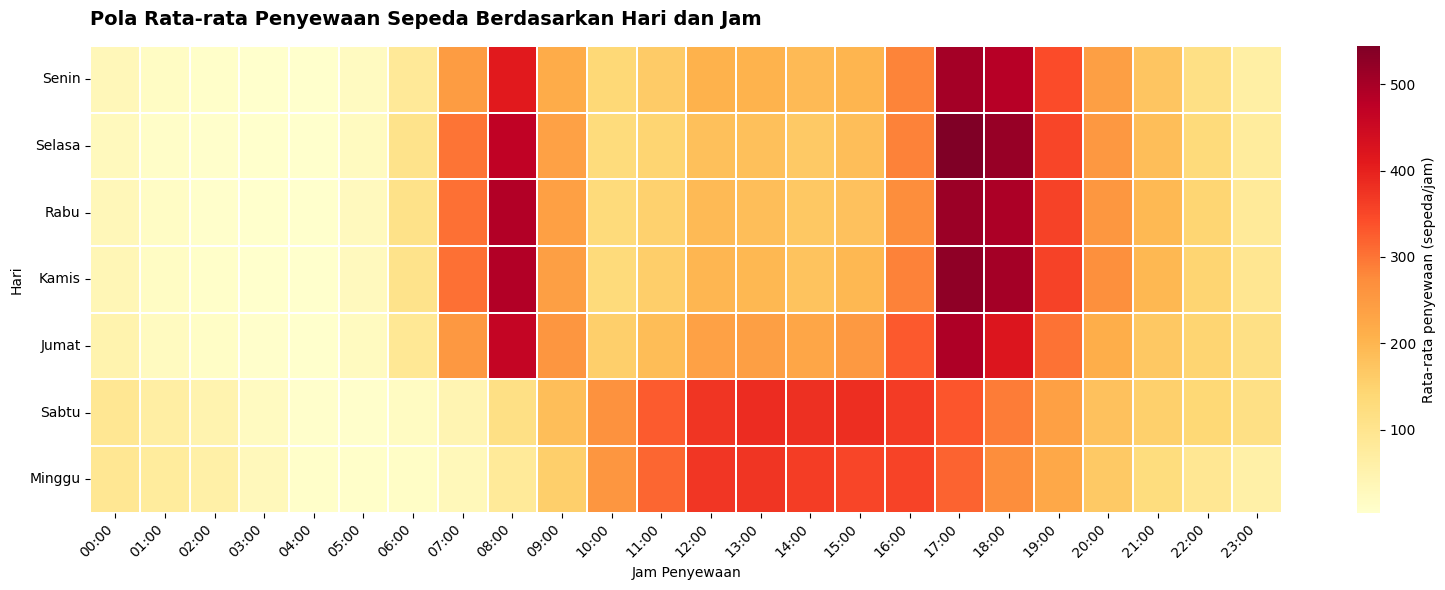

Jam Puncak Penyewaan pada Setiap Hari:
Senin: pukul 17:00 dengan rata-rata 502.4 penyewaan per jam
Selasa: pukul 17:00 dengan rata-rata 544.3 penyewaan per jam
Rabu: pukul 17:00 dengan rata-rata 513.1 penyewaan per jam
Kamis: pukul 17:00 dengan rata-rata 527.3 penyewaan per jam
Jumat: pukul 17:00 dengan rata-rata 492.4 penyewaan per jam
Sabtu: pukul 13:00 dengan rata-rata 385.4 penyewaan per jam
Minggu: pukul 13:00 dengan rata-rata 374.9 penyewaan per jam


In [107]:
# Membuat pemetaan kode hari menjadi nama hari
nama_hari = {
    0: "Minggu",
    1: "Senin",
    2: "Selasa",
    3: "Rabu",
    4: "Kamis",
    5: "Jumat",
    6: "Sabtu"
}

urutan_hari = [
    "Senin", "Selasa", "Rabu", "Kamis",
    "Jumat", "Sabtu", "Minggu"
]

# Menambahkan nama hari pada dataset per jam
hour_df["nama_hari"] = hour_df["weekday"].map(nama_hari)

# Menghitung rata-rata penyewaan berdasarkan hari dan jam
heatmap_data = hour_df.pivot_table(
    index="nama_hari",
    columns="hr",
    values="cnt",
    aggfunc="mean"
).reindex(
    index=urutan_hari,
    columns=range(24)
)

# Membuat visualisasi heatmap
fig, ax = plt.subplots(figsize=(16, 6))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    linewidths=0.3,
    linecolor="white",
    cbar_kws={
        "label": "Rata-rata penyewaan (sepeda/jam)"
    },
    ax=ax
)

ax.set_title(
    "Pola Rata-rata Penyewaan Sepeda Berdasarkan Hari dan Jam",
    fontsize=14,
    fontweight="bold",
    loc="left",
    pad=15
)

ax.set_xlabel("Jam Penyewaan")
ax.set_ylabel("Hari")

ax.set_xticks(np.arange(0.5, 24, 1))
ax.set_xticklabels(
    [f"{jam:02d}:00" for jam in range(24)],
    rotation=45,
    ha="right"
)

ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()


# Mengidentifikasi jam dengan rata-rata penyewaan tertinggi setiap hari
puncak_harian = heatmap_data.idxmax(axis=1)

print("Jam Puncak Penyewaan pada Setiap Hari:")

for hari, jam in puncak_harian.items():
    nilai = heatmap_data.loc[hari, jam]

    print(
        f"{hari}: pukul {int(jam):02d}:00 "
        f"dengan rata-rata {nilai:.1f} penyewaan per jam"
    )

In [108]:
# Membandingkan rata-rata puncak penyewaan
# antara hari kerja dan akhir pekan

hari_kerja = ["Senin", "Selasa", "Rabu", "Kamis", "Jumat"]
akhir_pekan = ["Sabtu", "Minggu"]

rata_puncak_kerja = heatmap_data.loc[
    hari_kerja
].max(axis=1).mean()

rata_puncak_akhir_pekan = heatmap_data.loc[
    akhir_pekan
].max(axis=1).mean()

selisih_puncak = (
    (rata_puncak_kerja - rata_puncak_akhir_pekan)
    / rata_puncak_akhir_pekan
) * 100

print(f"Rata-rata puncak hari kerja: "
      f"{rata_puncak_kerja:.2f} sepeda/jam")

print(f"Rata-rata puncak akhir pekan: "
      f"{rata_puncak_akhir_pekan:.2f} sepeda/jam")

print(f"Selisih intensitas puncak: "
      f"{selisih_puncak:.2f}%")

Rata-rata puncak hari kerja: 515.92 sepeda/jam
Rata-rata puncak akhir pekan: 380.15 sepeda/jam
Selisih intensitas puncak: 35.71%


**Penjelasan Hasil:**

Heatmap menunjukkan distribusi rata-rata penyewaan sepeda berdasarkan kombinasi hari dalam seminggu dan jam penyewaan selama periode 2011–2012.

Terdapat beberapa pola menarik yang dapat diamati:

1. **Pola hari kerja (Senin–Jumat)**

   Penyewaan sepeda menunjukkan pola puncak yang konsisten pada pukul 17.00. Seluruh hari kerja memiliki jam puncak yang sama, dengan rata-rata penyewaan berkisar antara 492,4 hingga 544,3 sepeda per jam.

   Selain itu, terlihat peningkatan penyewaan pada pukul 07.00–09.00. Pola ini mengindikasikan adanya keterkaitan antara aktivitas penyewaan dan mobilitas masyarakat pada jam berangkat serta pulang kerja.

2. **Pola akhir pekan (Sabtu–Minggu)**

   Berbeda dengan hari kerja, penyewaan pada akhir pekan mencapai puncaknya pada pukul 13.00. Rata-rata penyewaan mencapai 385,4 sepeda per jam pada Sabtu dan 374,9 sepeda per jam pada Minggu.

   Aktivitas penyewaan pada akhir pekan cenderung meningkat secara bertahap sejak pagi hingga siang hari, kemudian menurun menjelang malam. Pola ini menunjukkan karakteristik waktu penggunaan sepeda yang berbeda dibandingkan hari kerja.

3. **Perbandingan intensitas jam puncak**

   Rata-rata nilai puncak penyewaan pada hari kerja adalah 515,9 sepeda per jam, sedangkan pada akhir pekan sebesar 380,15 sepeda per jam.

   Artinya, rata-rata intensitas penyewaan pada jam puncak hari kerja sekitar 35,7% lebih tinggi dibandingkan akhir pekan. Perbedaan ini memperlihatkan bahwa permintaan pada hari kerja memiliki intensitas puncak yang lebih tinggi.

Secara keseluruhan, hasil heatmap memperlihatkan bahwa pola penyewaan sepeda tidak hanya dipengaruhi oleh waktu dalam sehari, tetapi juga memiliki karakteristik berbeda berdasarkan hari dalam seminggu. Hari kerja didominasi aktivitas pada jam berangkat dan pulang kerja, sedangkan akhir pekan menunjukkan peningkatan aktivitas menjelang siang hingga sore hari.

**Insight:**

**1. Pengelompokan Hari Berdasarkan Tingkat Keramaian**

- Distribusi tingkat keramaian menunjukkan perubahan antara 2011 dan 2012. Pada 2011, kategori Ramai mendominasi dengan 147 hari (40,3%), sedangkan pada 2012 kategori Normal menjadi yang terbanyak dengan 147 hari (40,2%).

- Persentase hari dalam kategori Sepi mengalami penurunan dari 33,4% pada 2011 menjadi 26,2% pada 2012. Hal ini menunjukkan bahwa proporsi hari dengan penyewaan relatif rendah semakin berkurang.

- Penggunaan batas kategori berdasarkan rata-rata masing-masing tahun memungkinkan perbandingan tingkat keramaian yang lebih proporsional, meskipun rata-rata penyewaan harian meningkat dari 3.405,8 pada 2011 menjadi 5.599,9 pada 2012.

**2. Analisis Pola Penyewaan Berdasarkan Hari dan Jam**

- Terdapat perbedaan pola waktu puncak antara hari kerja dan akhir pekan. Seluruh hari kerja mencapai puncak penyewaan pada pukul 17.00, sedangkan Sabtu dan Minggu mencapai puncaknya pada pukul 13.00.

- Selasa menjadi hari dengan rata-rata puncak penyewaan tertinggi, yaitu 544,3 sepeda per jam. Sementara itu, Minggu memiliki rata-rata puncak terendah sebesar 374,9 sepeda per jam.

- Rata-rata intensitas puncak penyewaan pada hari kerja mencapai 515,92 sepeda per jam, sedangkan akhir pekan sebesar 380,15 sepeda per jam. Dengan demikian, intensitas puncak hari kerja sekitar 35,71% lebih tinggi dibandingkan akhir pekan.

**Kesimpulan Analisis Lanjutan:**

Kedua analisis menunjukkan bahwa permintaan penyewaan sepeda memiliki variasi berdasarkan tingkat keramaian harian maupun waktu penggunaan. Pengelompokan tingkat keramaian memperlihatkan perubahan distribusi kategori penyewaan dari 2011 ke 2012, sedangkan analisis heatmap mengidentifikasi perbedaan jam puncak antara hari kerja dan akhir pekan. Hasil ini dapat menjadi dasar pertimbangan dalam mengoptimalkan ketersediaan armada, perencanaan operasional, dan penjadwalan pemeliharaan berdasarkan pola permintaan.

## Conclusion & Recommendation

## Conclusion

- **Conclusion Pertanyaan 1 – Pola Penyewaan Berdasarkan Jam**

  Penyewaan sepeda memiliki pola waktu yang berbeda antara hari kerja dan akhir pekan/libur. Pada hari kerja, penyewaan mencapai dua puncak, yaitu pukul 08.00 sebesar 477,0 sepeda per jam dan pukul 17.00 sebesar 525,3 sepeda per jam. Sementara itu, akhir pekan/libur mencapai puncak pada pukul 13.00 sebesar 372,7 sepeda per jam. Temuan ini menunjukkan bahwa aktivitas penyewaan pada hari kerja cenderung berkaitan dengan mobilitas pagi dan sore, sedangkan akhir pekan lebih terkonsentrasi pada aktivitas siang hari.

- **Conclusion Pertanyaan 2 – Pengaruh Cuaca dan Suhu terhadap Penyewaan**

  Kondisi cuaca dan suhu menunjukkan hubungan yang kuat dengan variasi jumlah penyewaan sepeda harian. Berdasarkan kondisi cuaca, rata-rata penyewaan tertinggi terjadi pada cuaca Cerah sebesar 4.876,8 sepeda per hari, sedangkan Hujan/Salju Ringan hanya sebesar 1.803,3 sepeda per hari atau 63,0% lebih rendah. Berdasarkan kategori suhu, penyewaan tertinggi terjadi pada kondisi Hangat (20–30°C) sebesar 5.661,7 sepeda per hari, sedangkan kondisi Dingin (<10°C) hanya sebesar 1.677,8 sepeda per hari. Kombinasi penyewaan terendah ditemukan pada kondisi Dingin dan Hujan/Salju Ringan sebesar 1.039 sepeda per hari, berdasarkan tiga hari pengamatan. Dengan demikian, kondisi lingkungan perlu dipertimbangkan dalam perencanaan operasional penyewaan.

- **Conclusion Pertanyaan 3 – Pertumbuhan Penyewaan Bulanan**

  Total penyewaan sepeda mengalami pertumbuhan dari 1.243.103 pada tahun 2011 menjadi 2.049.576 pada tahun 2012, atau meningkat sebesar 806.473 penyewaan (64,9%). Seluruh bulan menunjukkan pertumbuhan positif dibandingkan bulan yang sama pada tahun sebelumnya. Pertumbuhan tertinggi terjadi pada Maret sebesar 157,4%, sedangkan pertumbuhan paling lambat terjadi pada Juni sebesar 41,3%. Hasil ini menunjukkan adanya peningkatan penggunaan layanan secara keseluruhan, meskipun tingkat pertumbuhan berbeda pada setiap bulan.

- **Conclusion Analisis Lanjutan 1 – Pengelompokan Tingkat Keramaian**

  Pengelompokan menggunakan teknik *manual grouping* menunjukkan adanya perubahan distribusi tingkat keramaian antara tahun 2011 dan 2012. Pada 2011, kategori Ramai mendominasi dengan 147 hari (40,3%), sedangkan pada 2012 kategori Normal menjadi yang terbanyak dengan 147 hari (40,2%). Proporsi hari dalam kategori Sepi juga menurun dari 33,4% pada 2011 menjadi 26,2% pada 2012. Penggunaan batas kategori berdasarkan rata-rata masing-masing tahun membantu membandingkan tingkat keramaian secara lebih proporsional meskipun volume penyewaan kedua tahun berbeda.

- **Conclusion Analisis Lanjutan 2 – Pola Penyewaan Berdasarkan Hari dan Jam**

  Analisis *heatmap* menunjukkan bahwa seluruh hari kerja memiliki jam puncak penyewaan pada pukul 17.00, sedangkan Sabtu dan Minggu mencapai puncaknya pada pukul 13.00. Selasa menjadi hari dengan rata-rata puncak tertinggi sebesar 544,3 sepeda per jam, sementara Minggu memiliki rata-rata puncak terendah sebesar 374,9 sepeda per jam. Rata-rata intensitas puncak hari kerja sebesar 515,92 sepeda per jam, lebih tinggi 35,71% dibandingkan akhir pekan sebesar 380,15 sepeda per jam. Temuan ini memperkuat adanya perbedaan karakteristik permintaan penyewaan berdasarkan hari dan waktu.

**Rekomendasi Action Item:**

1. **Optimalisasi Distribusi Armada Berdasarkan Jam Sibuk**

   Pengelola disarankan meningkatkan kesiapan dan distribusi sepeda menjelang pukul 07.00–09.00 dan 17.00 pada hari kerja. Pada akhir pekan, ketersediaan armada dapat lebih difokuskan menjelang pukul 11.00–15.00. Strategi ini bertujuan mengantisipasi peningkatan permintaan pada periode puncak dan mengurangi risiko kekurangan sepeda.

2. **Penyesuaian Strategi Operasional Berdasarkan Kondisi Cuaca**

   Pengelola dapat menyesuaikan perencanaan ketersediaan armada berdasarkan prakiraan cuaca. Pada kondisi cuaca yang kurang mendukung, operasional dapat dievaluasi untuk menyesuaikan kebutuhan armada. Program promosi juga dapat dipertimbangkan ketika permintaan diperkirakan menurun, dengan tetap memperhatikan keselamatan pengguna.

3. **Optimalisasi Layanan Berdasarkan Kondisi Suhu**

   Mengingat penyewaan tertinggi terjadi pada kategori suhu Hangat (20–30°C), pengelola dapat memanfaatkan periode tersebut untuk meningkatkan kesiapan armada dan menjalankan kampanye pemasaran. Sebaliknya, pada kondisi suhu sangat dingin, strategi operasional dapat disesuaikan dengan perkiraan penurunan permintaan.

4. **Evaluasi Strategi Pertumbuhan Bulanan**

   Pengelola disarankan melakukan evaluasi strategi pemasaran pada bulan dengan pertumbuhan relatif rendah, khususnya Juni yang hanya tumbuh 41,3% pada 2012 dibandingkan Juni 2011. Evaluasi dapat dilakukan terhadap efektivitas promosi, aktivitas pemasaran, dan pola permintaan musiman untuk menyusun strategi pertumbuhan pada periode berikutnya.

5. **Penerapan Monitoring Tingkat Keramaian**

   Kategori Sepi, Normal, dan Ramai dapat digunakan sebagai indikator sederhana untuk memantau kondisi permintaan harian. Pengelola dapat menyesuaikan alokasi armada dan kebutuhan operasional berdasarkan kategori tersebut agar sumber daya dapat digunakan secara lebih efisien.

6. **Penjadwalan Pemeliharaan Armada**

   Pemeliharaan dan pemeriksaan rutin sepeda dapat dijadwalkan pada periode dengan aktivitas penyewaan relatif rendah, terutama pada dini hari. Penjadwalan ini perlu mempertimbangkan ketersediaan data per jam dan memastikan sepeda siap digunakan kembali sebelum memasuki jam sibuk.